In [16]:
import os
import glob
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully")

Libraries loaded successfully


In [17]:
DATA_DIR = Path("../data/raw/MachineLearningCVE")

print("Dataset directory:")
print(DATA_DIR.resolve())

if DATA_DIR.exists():
    print("\nDirectory exists.")
else:
    print("\nERROR: Dataset directory not found.")

Dataset directory:
/Users/admin/Desktop/federated-ids/data/raw/MachineLearningCVE

Directory exists.


In [39]:
csv_files = sorted(DATA_DIR.glob("*.csv"))

print(f"Number of CSV files found: {len(csv_files)}")
print()

for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {file.name}")

Number of CSV files found: 8

1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [19]:
print("CIC-IDS2017 file sizes:\n")

for file in csv_files:
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{file.name:<70} {size_mb:>10.2f} MB")

CIC-IDS2017 file sizes:

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                            73.55 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                        73.34 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv                                   55.62 MB
Monday-WorkingHours.pcap_ISCX.csv                                          168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv                 79.25 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv                      49.61 MB
Tuesday-WorkingHours.pcap_ISCX.csv                                         128.82 MB
Wednesday-workingHours.pcap_ISCX.csv                                       214.74 MB


In [20]:
sample_file = csv_files[0]

df_sample = pd.read_csv(sample_file)

print("File:", sample_file.name)
print("Rows:", len(df_sample))
print("Columns:", len(df_sample.columns))

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows: 225745
Columns: 79


In [21]:
df_sample.head()
print(f"Total columns: {len(df_sample.columns)}\n")

for i, column in enumerate(df_sample.columns):
    print(f"{i:02d}: {column}")

Total columns: 79

00:  Destination Port
01:  Flow Duration
02:  Total Fwd Packets
03:  Total Backward Packets
04: Total Length of Fwd Packets
05:  Total Length of Bwd Packets
06:  Fwd Packet Length Max
07:  Fwd Packet Length Min
08:  Fwd Packet Length Mean
09:  Fwd Packet Length Std
10: Bwd Packet Length Max
11:  Bwd Packet Length Min
12:  Bwd Packet Length Mean
13:  Bwd Packet Length Std
14: Flow Bytes/s
15:  Flow Packets/s
16:  Flow IAT Mean
17:  Flow IAT Std
18:  Flow IAT Max
19:  Flow IAT Min
20: Fwd IAT Total
21:  Fwd IAT Mean
22:  Fwd IAT Std
23:  Fwd IAT Max
24:  Fwd IAT Min
25: Bwd IAT Total
26:  Bwd IAT Mean
27:  Bwd IAT Std
28:  Bwd IAT Max
29:  Bwd IAT Min
30: Fwd PSH Flags
31:  Bwd PSH Flags
32:  Fwd URG Flags
33:  Bwd URG Flags
34:  Fwd Header Length
35:  Bwd Header Length
36: Fwd Packets/s
37:  Bwd Packets/s
38:  Min Packet Length
39:  Max Packet Length
40:  Packet Length Mean
41:  Packet Length Std
42:  Packet Length Variance
43: FIN Flag Count
44:  SYN Flag Count
45:  

In [22]:
df_sample.columns = df_sample.columns.str.strip()

print("Column names cleaned.")
print("Label column exists:", "Label" in df_sample.columns)

Column names cleaned.
Label column exists: True


In [23]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13  Bwd Packet

In [25]:
unique_values = df_sample.nunique().sort_values()

unique_values.head(20)

Fwd Avg Packets/Bulk    1
Bwd Avg Bytes/Bulk      1
Bwd Avg Packets/Bulk    1
Bwd Avg Bulk Rate       1
CWE Flag Count          1
Fwd Avg Bulk Rate       1
Fwd Avg Bytes/Bulk      1
Bwd PSH Flags           1
Fwd URG Flags           1
Bwd URG Flags           1
RST Flag Count          2
FIN Flag Count          2
ACK Flag Count          2
URG Flag Count          2
Fwd PSH Flags           2
ECE Flag Count          2
SYN Flag Count          2
PSH Flag Count          2
Label                   2
Down/Up Ratio           8
dtype: int64

In [26]:
label_counts = df_sample["Label"].value_counts()

print("Traffic classes:\n")
print(label_counts)

Traffic classes:

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [27]:
label_percentages = (
    df_sample["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(3)
)

print("Class distribution (%):\n")
print(label_percentages)

Class distribution (%):

Label
DDoS      56.713
BENIGN    43.287
Name: proportion, dtype: float64


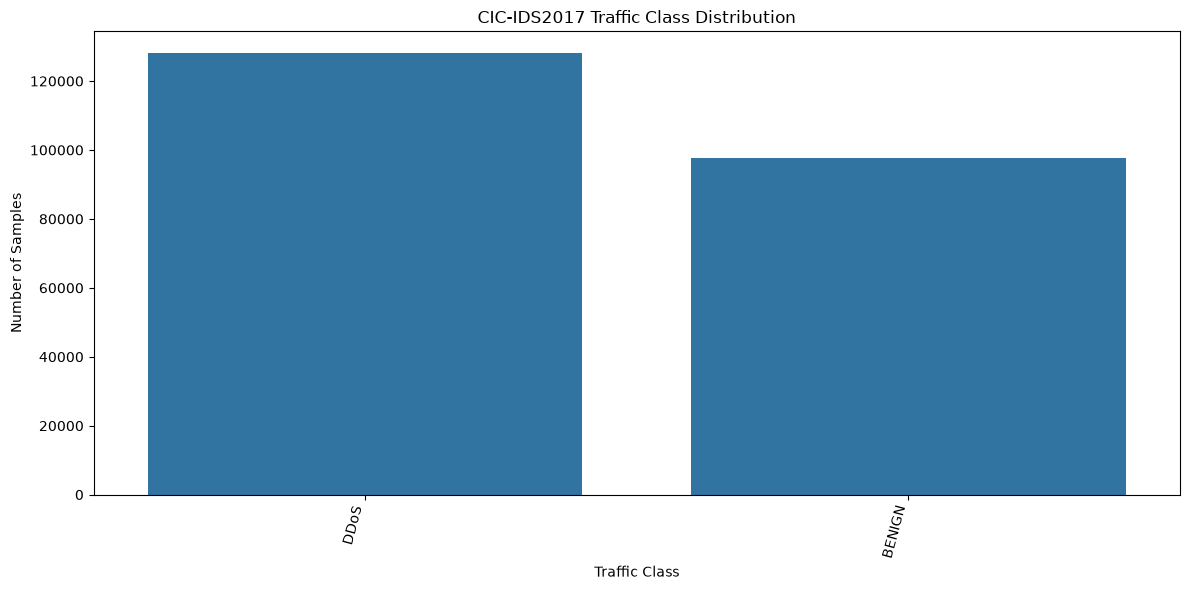

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.xticks(rotation=75, ha="right")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Samples")
plt.title("CIC-IDS2017 Traffic Class Distribution")

plt.tight_layout()
plt.show()

In [29]:
df_sample["BinaryLabel"] = (
    df_sample["Label"]
    .str.strip()
    .str.upper()
    .ne("BENIGN")
    .astype(int)
)

print(df_sample["BinaryLabel"].value_counts())

BinaryLabel
1    128027
0     97718
Name: count, dtype: int64


In [30]:
binary_counts = df_sample["BinaryLabel"].value_counts()

print("0 = BENIGN")
print("1 = ATTACK")
print()

print(binary_counts)

0 = BENIGN
1 = ATTACK

BinaryLabel
1    128027
0     97718
Name: count, dtype: int64


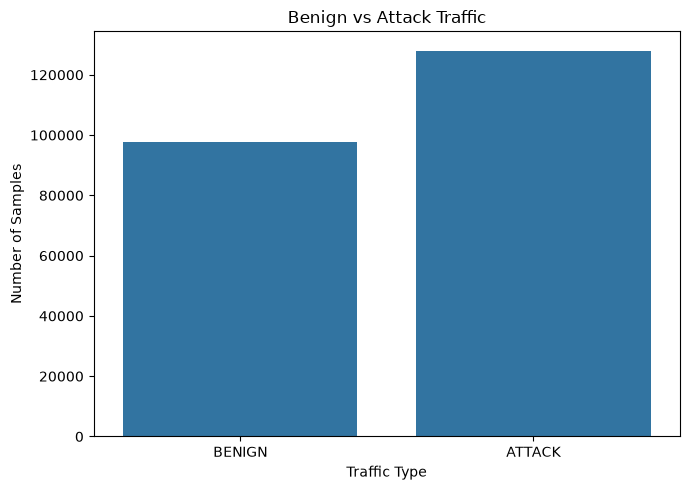

In [31]:
binary_labels = ["BENIGN", "ATTACK"]

plt.figure(figsize=(7, 5))

sns.barplot(
    x=binary_labels,
    y=[
        binary_counts.get(0, 0),
        binary_counts.get(1, 0)
    ]
)

plt.xlabel("Traffic Type")
plt.ylabel("Number of Samples")
plt.title("Benign vs Attack Traffic")

plt.tight_layout()
plt.show()

In [32]:
missing_values = df_sample.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

if len(missing_values) == 0:
    print("No missing values found.")
else:
    print(missing_values)

Flow Bytes/s    4
dtype: int64


In [33]:
numeric_columns = df_sample.select_dtypes(
    include=np.number
).columns

infinite_values = np.isinf(
    df_sample[numeric_columns]
).sum()

infinite_values = infinite_values[
    infinite_values > 0
].sort_values(ascending=False)

if len(infinite_values) == 0:
    print("No infinite values found.")
else:
    print(infinite_values)

Flow Packets/s    34
Flow Bytes/s      30
dtype: int64


In [34]:
duplicate_count = df_sample.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 2633
